# Explainable Fake News Detection System
## 1. Dataset Understanding

### Importing the libraries

We import **pandas** to load and work with tabular data, and **NumPy** for numerical operations. These libraries provide the basic tools needed for dataset handling. The imports do not change the dataset; they make the libraries available to the notebook.

In [1]:
import pandas as pd
import numpy as np

### Loading the dataset

`pd.read_csv()` reads the WELFake CSV file and stores it in a pandas DataFrame named `df`. A DataFrame is a table with rows and columns. The file path must point to the CSV on the computer where this notebook is running.

In [2]:
df = pd.read_csv(
    r"C:\Users\Justina\OneDrive\Desktop\ML_project\explainable-fake-news-detection\data\WELFake_Dataset.csv"
)

### Previewing the dataset

`df.head()` displays the first five rows by default. We use it to check whether the file loaded correctly and to understand what one record looks like before cleaning or modeling.

In [3]:
df.head()


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


### Checking dataset dimensions

`df.shape` returns a pair: `(number_of_rows, number_of_columns)`. Rows represent news articles and columns represent their attributes. This gives us the dataset's starting size.

In [4]:
df.shape

(72134, 4)

### Checking column names

`df.columns` lists the available fields. We need to identify the columns containing the news title, article text, and target label, and notice any extra index-like column that may not be useful for prediction.

In [5]:
df.columns

Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='str')

### Checking data types and non-null counts

`df.info()` reports each column's data type and how many values are non-null. This helps identify missing data and confirm which columns are numeric or text-based.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  72134 non-null  int64
 1   title       71576 non-null  str  
 2   text        72095 non-null  str  
 3   label       72134 non-null  int64
dtypes: int64(2), str(2)
memory usage: 2.2 MB


### Counting the target labels

`value_counts()` counts how many records belong to each label. In this dataset, label `0` represents Fake and label `1` represents Real, based on the dataset's label mapping. The counts help us understand whether one class heavily outweighs the other.

In [7]:
df['label'].value_counts()

label
1    37106
0    35028
Name: count, dtype: int64

### Checking unique label values

`unique()` displays the distinct values in the label column. We use it to verify that the target contains the expected classes, rather than unexpected or incorrectly formatted values.

In [8]:
df['label'].unique()

array([1, 0])

### Finding missing values by column

`isnull()` marks missing entries as `True`, and `sum()` counts them in each column. This identifies which fields need attention before text processing.

In [9]:
df.isnull().sum()

Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

### Counting all missing values

The second `sum()` adds the per-column missing-value counts to give one total for the whole DataFrame. It is a quick overall check, while the previous cell shows where the missing values occur.

In [10]:
df.isnull().sum().sum()

np.int64(597)

### Measuring missing-value percentages

We divide each column's missing-value count by the total number of rows and multiply by 100. Percentages make it easier to judge the scale of missing data in each column.

In [11]:
(df.isnull().sum() / len(df)) * 100

Unnamed: 0    0.000000
title         0.773560
text          0.054066
label         0.000000
dtype: float64

### Checking fully duplicated rows

`duplicated().sum()` counts rows that exactly repeat an earlier row across all columns. This is an initial duplicate check; later we also check duplicates using only the meaningful news fields.

In [12]:
df.duplicated().sum()

np.int64(0)

### 2. Data Cleaning and Preprocessing

### Checking duplicates in meaningful fields

Here we check repeated combinations of `title`, `text`, and `label`. This is more relevant than checking every column because the `Unnamed: 0` index-like field may differ even when the actual news record is repeated.

In [14]:
df[['title', 'text', 'label']].duplicated().sum()

np.int64(8456)

### Visualizing the class distribution

A count plot displays the number of records for each label. The x-axis shows the class and the y-axis shows its count. This visual check helps us see whether the dataset is reasonably balanced.

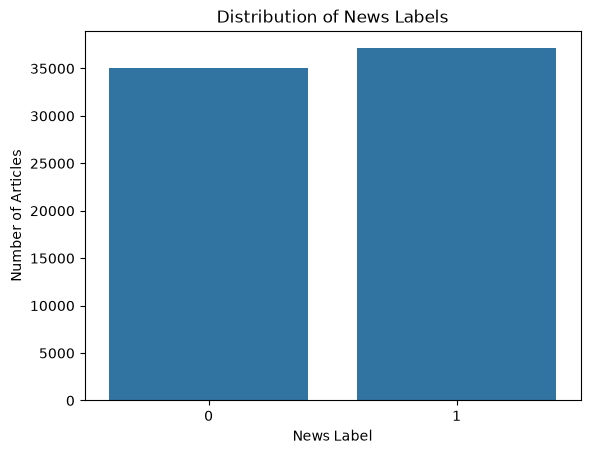

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='label')

plt.title("Distribution of News Labels")
plt.xlabel("News Label")
plt.ylabel("Number of Articles")

plt.show()

### Observation – Class Distribution

The dataset contains 72,134 news articles divided into two
categories: 0 and 1.

- Label 0: 35,028 articles (48.56%)
- Label 1: 37,106 articles (51.44%)

The dataset is relatively balanced, with a small difference
between the two classes. Therefore, no immediate class
balancing technique is required.

### Inspecting rows with a missing title

This filter selects records where `title` is missing but `text` is available. We inspect these rows to understand whether useful article content remains even when the title is absent.

In [16]:
df[df['title'].isnull() & df['text'].notnull()].head()

,Unnamed: 0,title,text,label
1,1,NaN,Did they post their votes for Hillary already?,1
43,43,NaN,True. Hillary needs a distraction and what bet...,1
162,162,NaN,All eyes on Electoral delegates. The People kn...,1
185,185,NaN,Cool,1
269,269,NaN,A leading US senator: US Supporting War in Syr...,1


### Checking records missing both title and text

This condition finds records with no title and no article text. Such records contain no news content for a text classifier to learn from.

In [17]:
df[df['title'].isnull() & df['text'].isnull()]

,Unnamed: 0,title,text,label


### Counting records missing both text fields

`.shape` reports the number of rows and columns in the filtered result. It confirms how many records have neither a title nor article text.

In [18]:
df[df['title'].isnull() & df['text'].isnull()].shape

(0, 4)

### Inspecting rows with missing article text

This filter finds records where the article text is missing but a title exists. The next cleaning step removes these rows because the workflow uses the article text as a required field.

In [19]:
df[df['text'].isnull() & df['title'].notnull()].head()

,Unnamed: 0,title,text,label
2457,2457,Après le succès de « Mariés au premier regard ...,NaN,1
3534,3534,Elections US : les premières estimations donne...,NaN,1
3709,3709,110% des Américains assurent qu’ils continuero...,NaN,1
5612,5612,Des millions d’Américains recherchent massivem...,NaN,1
6270,6270,Vladimir Poutine est élu 45e Président des Eta...,NaN,1


### 3. Handling Missing Values

### Removing rows with missing article text

`dropna(subset=['text'])` removes only rows whose `text` value is missing. We retain rows with a missing title because the title can be filled with an empty string later, while the article text is required for this project.

In [20]:
df_clean = df.dropna(subset=['text'])

### Verifying missing values after filtering

We run the missing-value count again to check the result of the previous cleaning step. Some missing titles may remain at this point; they are handled when the title and text are combined.

In [21]:
df_clean.isnull().sum()

Unnamed: 0      0
title         558
text            0
label           0
dtype: int64

### Counting duplicate news records

This checks duplicates using title, text, and label after rows with missing article text have been removed. It tells us how many repeated news records remain before removing them.

In [22]:
df_clean.duplicated(subset=['title', 'text', 'label']).sum()

np.int64(8456)

### 4. Removing Duplicate Records

### Removing duplicate news records

`drop_duplicates()` keeps the first occurrence of each unique combination of title, text, and label and removes later repeats. This prevents identical records from being counted multiple times during model training.

In [23]:
df_clean = df_clean.drop_duplicates(
    subset=['title', 'text', 'label']
)

### Verifying duplicate removal

The first print displays the new DataFrame dimensions. The second check should return zero for the selected fields, confirming that those duplicate combinations have been removed.

In [24]:
print("Shape after removing duplicates:", df_clean.shape)

print(
    "Remaining duplicates:",
    df_clean.duplicated(subset=['title', 'text', 'label']).sum()
)

Shape after removing duplicates: (63639, 4)
Remaining duplicates: 0


### Removing the extra index column

`Unnamed: 0` is an index-like column from the source CSV, not a meaningful property of the news article. We drop it so it is not accidentally treated as useful data in later steps.

In [25]:
df_clean = df_clean.drop(columns=['Unnamed: 0'])

### Checking the remaining columns

This confirms the columns left after dropping the extra index field. We expect to retain the title, article text, label, and then create a combined content field.

In [26]:
df_clean.columns

Index(['title', 'text', 'label'], dtype='str')

### Handling missing titles

`fillna('')` replaces missing title values with an empty string in the returned Series. This prevents missing titles from becoming the text value `NaN` when we combine title and article text. The next cell applies this handling during assignment.

In [27]:
df_clean['title'].fillna('')

0        LAW ENFORCEMENT ON HIGH ALERT Following Threat...
1                                                         
2        UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3        Bobby Jindal, raised Hindu, uses story of Chri...
4        SATAN 2: Russia unvelis an image of its terrif...
                               ...                        
72127    WIKILEAKS EMAIL SHOWS CLINTON FOUNDATION FUNDS...
72129    Russians steal research on Trump in hack of U....
72130     WATCH: Giuliani Demands That Democrats Apolog...
72131    Migrants Refuse To Leave Train At Refugee Camp...
72132    Trump tussle gives unpopular Mexican leader mu...
Name: title, Length: 63639, dtype: str

### 5. Creating Combined Text Column

### Combining title and article text

We create a new `content` column by joining the title, a space, and the article text. Missing titles or text values are replaced with empty strings during the combination. Using both fields gives the model more of the available news wording to analyze.

In [28]:
df_clean['content'] = (
    df_clean['title'].fillna('') + ' ' +
    df_clean['text'].fillna('')
)

### Inspecting the combined content

This displays the title, original article text, and newly created `content` side by side. We use it to verify that the two text fields were joined in the intended order.

In [29]:
df_clean[['title', 'text', 'content']].head()

,title,text,content
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,LAW ENFORCEMENT ON HIGH ALERT Following Threat...
1,NaN,Did they post their votes for Hillary already?,Did they post their votes for Hillary already?
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,"Bobby Jindal, raised Hindu, uses story of Chri..."
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",SATAN 2: Russia unvelis an image of its terrif...


### Checking the combined text for missing values

This checks whether any missing values remain in the new `content` column. A clean text field is important because the following operations expect strings.

In [30]:
df_clean['content'].isnull().sum()

np.int64(0)

### 6. Text Cleaning

### Converting text to lowercase

`.str.lower()` converts all letters in the content to lowercase. This reduces duplicate forms such as `News` and `news` being treated as different tokens by the vectorizer.

In [31]:
df_clean['content'] = df_clean['content'].str.lower()

### Importing regular expressions

`re` is Python's regular-expression library. We use it to find and replace patterns in text, such as punctuation, web links, and repeated whitespace.

In [32]:
import re

### Removing URLs

The regular expression matches web addresses beginning with `http://`, `https://`, or `www.` and removes them. Links usually do not provide the article's natural-language content that this model is intended to classify.

In [33]:
df_clean['content'] = df_clean['content'].apply(
    lambda x: re.sub(r'https?://\S+|www\.\S+', '', x)
)

### Removing punctuation and special symbols

The pattern `[\w\s]` keeps word characters and whitespace; `[^...]` means characters outside that set. `re.sub(..., '', x)` replaces those other characters with an empty string. Numbers and underscores are retained by `\w`, and whitespace is retained by `\s`.

In [34]:
df_clean['content'] = df_clean['content'].apply(
    lambda x: re.sub(r'[^\w\s]', '', x)
)

### Normalizing whitespace

The pattern `\s+` matches one or more whitespace characters, including repeated spaces and line breaks. We replace them with one space and use `strip()` to remove spaces at the beginning and end of each article.

In [35]:
df_clean['content'] = df_clean['content'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

### Inspecting cleaned text

This prints one example after text cleaning. It lets us visually confirm that the text is lowercase, URLs and punctuation have been removed, and whitespace has been normalized.

In [36]:
print(df_clean['content'].iloc[0])

law enforcement on high alert following threats against cops and whites on 911by blacklivesmatter and fyf911 terrorists video no comment is expected from barack obama members of the fyf911 or fukyoflag and blacklivesmatter movements called for the lynching and hanging of white people and cops they encouraged others on a radio show tuesday night to turn the tide and kill white people and cops to send a message about the killing of black people in americaone of the fyoflag organizers is called sunshine she has a radio blog show hosted from texas called sunshine s fing opinion radio show a snapshot of her fyf911 lolatwhitefear twitter page at 953 pm shows that she was urging supporters to call now fyf911 tonight we continue to dismantle the illusion of white below is a snapshot twitter radio call invite fyf911the radio show aired at 1000 pm eastern standard timeduring the show callers clearly call for lynching and killing of white peoplea 239 minute clip from the radio show can be heard h

### 7. Stop-Word Removal Using spaCy

### Loading spaCy

We import spaCy and load the English medium pipeline. In this notebook, the pipeline provides spaCy's English stop-word list and tokenizer. We use the tokenizer to split each article into tokens before filtering stop words.

In [37]:
import spacy
nlp = spacy.load('en_core_web_md')

### Getting spaCy's stop-word set

`nlp.Defaults.stop_words` provides a set of common English words that are often less useful for distinguishing document topics. A set supports efficient membership checks while filtering tokens.

In [38]:
stop_words = nlp.Defaults.stop_words.copy()

### Checking the stop-word list size

`len(stop_words)` returns how many words are currently in the stop-word set. This is a simple check that the list has been loaded.

In [39]:
print(len(stop_words))

326


### Checking one word's stop-word status

`nlp.vocab['between'].is_stop` checks whether spaCy marks the word `between` as a stop word. This demonstrates how spaCy stores stop-word information for vocabulary items.

In [40]:
nlp.vocab['between'].is_stop

True

### Inspecting important negation words

We check common words including `not`, `no`, and `never`. These words can reverse the meaning of a sentence, so removing them could remove useful clues from a fake-news classification task.

In [41]:
for word in ["the", "is", "not", "no", "never"]:
    print(word, nlp.vocab[word].is_stop)

the True
is True
not True
no True
never True


### Preserving negation words

`discard()` removes a word from the stop-word set if it is present, without raising an error if it is absent. We remove `not`, `no`, and `never` from the words to be filtered so their meaning is retained in the article text.

In [42]:
stop_words.discard("not")
stop_words.discard("no")
stop_words.discard("never")

### Removing stop words in batches

We process the articles in batches of 500 to avoid sending the entire dataset through the tokenizer at once. `nlp.tokenizer.pipe()` tokenizes each article efficiently. For each document, we keep tokens whose lowercase form is not in `stop_words`, join them back into a string, and append the result to `filtered_texts`. Finally, we store the processed strings in `content_no_stopwords`. The progress message shows how many rows have been processed. This step removes common words while preserving the negation words selected above.

In [43]:
filtered_texts = []

batch_size = 500

for i in range(0, len(df_clean), batch_size):

    batch = df_clean['content'].iloc[i:i + batch_size].fillna('').astype(str)

    docs = nlp.tokenizer.pipe(batch, batch_size=batch_size)

    for doc in docs:
        filtered_texts.append(
            ' '.join(
                token.text for token in doc
                if token.text.lower() not in stop_words
            )
        )

    print(f"Processed {min(i + batch_size, len(df_clean))} / {len(df_clean)}")

df_clean['content_no_stopwords'] = filtered_texts

print("Stop-word removal completed!")

Processed 500 / 63639
Processed 1000 / 63639
Processed 1500 / 63639
Processed 2000 / 63639
Processed 2500 / 63639
Processed 3000 / 63639
Processed 3500 / 63639
Processed 4000 / 63639
Processed 4500 / 63639
Processed 5000 / 63639
Processed 5500 / 63639
Processed 6000 / 63639
Processed 6500 / 63639
Processed 7000 / 63639
Processed 7500 / 63639
Processed 8000 / 63639
Processed 8500 / 63639
Processed 9000 / 63639
Processed 9500 / 63639
Processed 10000 / 63639
Processed 10500 / 63639
Processed 11000 / 63639
Processed 11500 / 63639
Processed 12000 / 63639
Processed 12500 / 63639
Processed 13000 / 63639
Processed 13500 / 63639
Processed 14000 / 63639
Processed 14500 / 63639
Processed 15000 / 63639
Processed 15500 / 63639
Processed 16000 / 63639
Processed 16500 / 63639
Processed 17000 / 63639
Processed 17500 / 63639
Processed 18000 / 63639
Processed 18500 / 63639
Processed 19000 / 63639
Processed 19500 / 63639
Processed 20000 / 63639
Processed 20500 / 63639
Processed 21000 / 63639
Processed 21

### 8. TF-IDF Vectorization

### Importing TF-IDF

`TfidfVectorizer` converts text documents into numerical feature vectors. Machine-learning algorithms such as Logistic Regression need numerical inputs rather than raw sentences.

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

### Creating the TF-IDF vectorizer

`max_features=5000` limits the vocabulary to at most 5,000 features. TF-IDF gives a word a higher weight when it is useful within a document but not common across all documents. The vectorizer learns its vocabulary and inverse-document-frequency weights when `fit` or `fit_transform` is called.

In [45]:
tfidf = TfidfVectorizer(max_features=5000)

### Separating the target labels

The `label` column is the target (`y`) that the model must learn to predict. The text content will be the input features (`X`). Keeping the target separate prevents it from being included in the text features.

In [46]:
# Select the target column (0 = Fake, 1 = Real)
y = df_clean['label']

### Checking target label counts

This displays the number of examples for each target class. It is a quick confirmation that the labels are available before the train-test split.

In [47]:
# The target labels are stored separately from the news text.
print(y.value_counts())

label
0    34791
1    28848
Name: count, dtype: int64


### 9. Model Training – Train-Test Split

### Importing the train-test split function

`train_test_split` divides the available examples into a training portion and a testing portion. The training data is used to fit the model; the testing data is held back to evaluate performance on unseen examples.

In [48]:
from sklearn.model_selection import train_test_split

### Splitting text before TF-IDF fitting

We split the cleaned text and labels, reserving 20% for testing. `random_state=42` makes the random split reproducible. `stratify=y` keeps approximately the same fake/real class proportions in both sets. We then fit TF-IDF only on `X_train_text`; this prevents test-set vocabulary information from leaking into training. `transform()` applies the already learned vocabulary and weights to test text without learning from it.

In [49]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df_clean['content_no_stopwords'], y, test_size=0.2, random_state=42, stratify=y
)

# Learn the vocabulary and IDF weights from training text only.
X_train = tfidf.fit_transform(X_train_text)

# Apply the same learned vocabulary and weights to unseen test text.
X_test = tfidf.transform(X_test_text)

### Checking TF-IDF matrix dimensions

The shape of each matrix is `(number of articles, number of features)`. This check belongs after the train-test split and TF-IDF transformation because `X_train` and `X_test` are created in that step. The training and test matrices should have the same number of feature columns, while their row counts reflect the 80/20 split.

In [50]:
print('Training feature shape:', X_train.shape)
print('Testing feature shape:', X_test.shape)

Training feature shape: (50911, 5000)
Testing feature shape: (12728, 5000)


### Checking split label dimensions

These shapes show how many target labels belong to the training and testing sets. Each label count should match the number of rows in its corresponding feature matrix.

In [51]:
print('Training labels:', y_train.shape)
print('Testing labels:', y_test.shape)

Training labels: (50911,)
Testing labels: (12728,)


### 10. Logistic Regression Model Training

### Training Logistic Regression

Logistic Regression is a supervised classification algorithm. It learns a relationship between the TF-IDF features and the known labels. `max_iter=1000` allows the solver up to 1,000 iterations to find model parameters; it is not the number of training records. `fit()` trains the model using the training feature matrix and labels.

In [52]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### 11. Model Prediction

### Predicting labels for test articles

`predict()` applies the trained model to the held-out test feature matrix and returns one predicted class for each article. These predictions are stored in `y_pred` and are compared with the true labels during evaluation.

In [53]:
y_pred = model.predict(X_test)

### Previewing predictions

This prints the first ten predicted labels. The values use the dataset's class mapping: 0 for Fake and 1 for Real.

In [54]:
print(y_pred[:10])

[1 0 0 0 0 0 1 1 0 0]


### 12. Model Evaluation

### Importing the accuracy metric

`accuracy_score` measures the fraction of test examples whose predicted labels match their actual labels. It gives an overall summary, but it should be considered alongside precision, recall, F1-score, and the confusion matrix.

In [55]:
from sklearn.metrics import accuracy_score

### Calculating accuracy

We compare `y_test` (the correct labels) with `y_pred` (the model's predictions). The result is a proportion between 0 and 1; multiplying by 100 expresses it as a percentage if desired.

In [56]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.9508956631049654


### Importing the classification report

`classification_report` calculates precision, recall, F1-score, and support for each class. These metrics show different aspects of performance and help reveal errors that a single accuracy value can hide.

In [57]:
from sklearn.metrics import classification_report

### Displaying classification metrics

Precision measures how many predictions for a class were correct. Recall measures how many actual examples of that class were found. F1-score is the harmonic mean of precision and recall. Support is the number of actual test examples in that class.

In [58]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.96      0.96      6958
           1       0.95      0.95      0.95      5770

    accuracy                           0.95     12728
   macro avg       0.95      0.95      0.95     12728
weighted avg       0.95      0.95      0.95     12728



### Importing the confusion matrix

A confusion matrix counts correct and incorrect predictions for each class. It helps us see which kinds of mistakes the classifier makes.

In [59]:
from sklearn.metrics import confusion_matrix

### Creating the confusion matrix

`confusion_matrix(y_test, y_pred)` compares actual labels with predicted labels. In scikit-learn, rows represent actual classes and columns represent predicted classes. For labels ordered as 0 then 1, the diagonal contains correct predictions and the off-diagonal cells contain errors.

In [60]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[6646  312]
 [ 313 5457]]


### Importing plotting libraries

Matplotlib provides plotting functions, while Seaborn makes it easier to create a readable heatmap. We use them to visualize the confusion matrix.

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

### Visualizing the confusion matrix

The heatmap displays the count in each actual-versus-predicted category. `annot=True` writes the counts in the cells and `fmt='d'` displays them as integers. The axis labels identify actual and predicted classes.

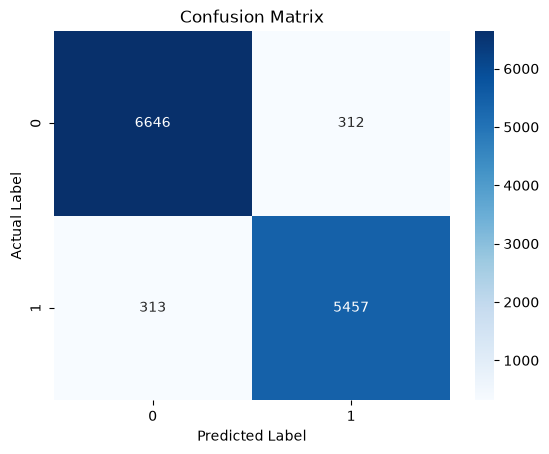

In [62]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

### 13. LIME Explainability

### Installing LIME

LIME is a library for explaining individual model predictions. The `%pip` command installs it in the environment used by the current Jupyter kernel. If it is already installed, pip reports that no installation is needed.

In [64]:
%pip install lime
import warnings
warnings.filterwarnings('ignore')

Note: you may need to restart the kernel to use updated packages.


### Importing the LIME text explainer

`LimeTextExplainer` is designed to explain predictions made from text. It creates perturbed versions of a sample text and observes how the model's output changes.

In [65]:
from lime.lime_text import LimeTextExplainer

### Creating the LIME explainer

We provide the class names in the same order as the model's probability columns: index 0 is Fake and index 1 is Real. This allows LIME to display human-readable class names in its explanation.

In [66]:
explainer = LimeTextExplainer(class_names=['Fake', 'Real'])

### 14. LIME Prediction Function

### Defining the probability prediction function

LIME needs a function that accepts a list of text strings and returns a probability for each class. `tfidf.transform()` converts those strings using the vocabulary learned during training; it does not refit the vectorizer. `model.predict_proba()` returns the model's estimated probabilities for Fake and Real. The input to this function must already follow the same text-cleaning and stop-word-removal process used during training.

In [67]:
def predict_probability(text):
    text_tfidf = tfidf.transform(text)

    return model.predict_proba(text_tfidf)

### Selecting a sample article

We choose one processed article from the cleaned dataset to demonstrate prediction and explanation. Using `content_no_stopwords` ensures this example has already undergone the same preprocessing used to train the model.

In [68]:
sample_text = df_clean['content_no_stopwords'].iloc[1]

### 15. News Prediction with Probability

### Predicting the sample article and showing probabilities

The function returns two probabilities for this sample: the first is for Fake and the second is for Real, following the class order defined by the training labels and LIME setup. The `if` statement selects the class with the larger probability. The printed percentages show the model's estimated confidence for each class; they are not a guarantee that the prediction is correct.

In [69]:
probability = predict_probability([sample_text])

if probability[0][0] > probability[0][1]:
    print("Prediction: Fake News")
else:
    print("Prediction: Real News")

print("Fake News Probability:", round(probability[0][0] * 100, 2), "%")
print("Real News Probability:", round(probability[0][1] * 100, 2), "%")



Prediction: Real News
Fake News Probability: 0.18 %
Real News Probability: 99.82 %


### 16. LIME Explanation

### Generating a local explanation with LIME

`explain_instance()` explains this one article rather than the whole model. LIME creates nearby text variations, queries the prediction function, and fits a simple local explanation around the sample. `num_features=10` asks it to show up to ten influential text features. The sign and size of a feature's weight must be interpreted for the specific class being explained; do not assume a positive weight always means Real.

In [70]:
explanation = explainer.explain_instance(
    sample_text,
    predict_probability,
    num_features=10
)

### Plotting the LIME explanation

`as_pyplot_figure()` converts the explanation into a Matplotlib figure, and `plt.show()` displays it. The plot shows which words support or oppose the selected class according to the local explanation.

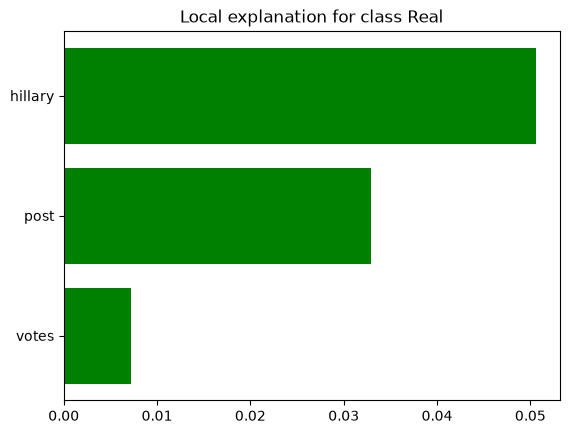

In [71]:
explanation.as_pyplot_figure()
plt.show()

### Viewing LIME feature weights as text

`as_list()` returns the feature names and their local weights as Python pairs. These weights describe the local surrogate explanation, not universal importance across the entire dataset. To interpret their direction correctly, specify and inspect the class label being explained.

In [72]:
print(explanation.as_list())

[(np.str_('hillary'), 0.050614443731109245), (np.str_('post'), 0.03293375033476839), (np.str_('votes'), 0.007247670934184014)]
